<a href="https://colab.research.google.com/github/Nesrineshnoun/physiophathologie-tp3/blob/main/M2_PCP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
Good morning

SyntaxError: invalid syntax (1700438559.py, line 1)

In [8]:
from google.colab import drive
import zipfile
import os

# Monter Google Drive
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Frontiers-Machine Learning.zip'

# Vérifier si le fichier existe et lister son contenu
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        print(f"Le fichier ZIP contient {len(zip_ref.namelist())} fichiers :\n")
        for file in zip_ref.namelist()[:30]:  # Afficher les 30 premiers fichiers
            print(file)
        if len(zip_ref.namelist()) > 30:
            print("... et plus encore.")
else:
    print(f"Le fichier n'a pas été trouvé à l'emplacement : {zip_path}. Veuillez vérifier le chemin d'accès.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Le fichier ZIP contient 1 fichiers :

Frontiers-Machine Learning/Cantor_machineclean-opendepository.xlsx


In [9]:
import pandas as pd
import zipfile
import os

# Chemin d'extraction
extract_path = '/content/extracted_files'
os.makedirs(extract_path, exist_ok=True)

# Extraction du fichier Excel du ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Recherche du fichier Excel
excel_file = os.path.join(extract_path, 'Frontiers-Machine Learning/Cantor_machineclean-opendepository.xlsx')

if os.path.exists(excel_file):
    # Lecture des données
    df = pd.read_excel(excel_file)
    print("Données chargées avec succès !\n")
    print("Aperçu des colonnes et des types de données :")
    display(df.info())
    print("\n5 premières lignes :")
    display(df.head())
else:
    print("Le fichier Excel n'a pas pu être localisé.")

Données chargées avec succès !

Aperçu des colonnes et des types de données :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8706 entries, 0 to 8705
Data columns (total 36 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Count           8299 non-null   float64       
 1   Observation     8300 non-null   float64       
 2   Date            8300 non-null   datetime64[ns]
 3   Data_Points     8299 non-null   float64       
 4   Total_Steps     8299 non-null   float64       
 5   Total_MI        8299 non-null   float64       
 6   Lying_time      8299 non-null   object        
 7   Lying_bouts     8299 non-null   float64       
 8   lying_daily     8299 non-null   float64       
 9   IdSeq           8300 non-null   float64       
 10  Gender          8300 non-null   float64       
 11  Season          8300 non-null   float64       
 12  Feederage       8300 non-null   float64       
 13  SENDER          8187 non-null 

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


None


5 premières lignes :


,Count,Observation,Date,Data_Points,Total_Steps,Total_MI,Lying_time,Lying_bouts,lying_daily,IdSeq,...,DPARITY,Pen,PERSON_SCORING,Fecal,Temp_score,Temp,Weight,Breath,Pneuday,agefeeder
0,4298.0,3.0,2018-12-19,96.0,535.0,2652.0,20:06:46,18.0,20.0,79.0,...,3.0,3.0,Melissa,1.0,0.0,38.3,NaN,0.0,NaN,2.0
1,4299.0,4.0,2018-12-20,96.0,516.0,2551.0,20:16:02,18.0,20.0,79.0,...,3.0,3.0,Melissa,1.0,0.0,37.6,44.7,0.0,NaN,2.0
2,4300.0,5.0,2018-12-21,96.0,543.0,2891.0,19:51:21,24.0,19.0,79.0,...,3.0,3.0,Melissa,2.0,0.0,38.2,NaN,0.0,NaN,2.0
3,4301.0,6.0,2018-12-22,96.0,333.0,1960.0,19:48:14,18.0,19.0,79.0,...,3.0,3.0,Melissa,2.0,0.0,38.2,NaN,0.0,NaN,2.0
4,4302.0,7.0,2018-12-23,96.0,669.0,3613.0,17:46:10,16.0,17.0,79.0,...,3.0,3.0,Melissa,2.0,0.0,38.1,NaN,0.0,NaN,2.0


In [10]:
# Identification automatique suggérée pour X (variables explicatives) et y (variable cible/activité biologique)
# Habituellement, la dernière colonne ou une colonne contenant des scores/activités/classes est choisie comme 'y'

print("Suggestion d'identification des variables :")
columns = df.columns.tolist()

# Par exemple, si la dernière colonne représente l'activité ou la cible :
target_col = columns[-1]
feature_cols = columns[:-1]

print(f"-> Variable cible suggérée (y) : {target_col}")
print(f"-> Caractéristiques suggérées (X) : {feature_cols[:5]} ... (Total de {len(feature_cols)} colonnes)")

Suggestion d'identification des variables :
-> Variable cible suggérée (y) : agefeeder
-> Caractéristiques suggérées (X) : ['Count', 'Observation', 'Date', 'Data_Points', 'Total_Steps'] ... (Total de 35 colonnes)


### Signification Biologique des Cibles ($y$) Possibles

Dans cette étude vétérinaire/biologique sur la santé des jeunes veaux, voici les trois principales variables cibles ($y$) qu'un modèle de Machine Learning peut chercher à prédire :

1. **`Pneuday` (Pneumonie - Pathologie Respiratoire) :**
   * *Signification :* Le jour de l'apparition de la pneumonie bovine. Prédire cette variable permet une détection précoce pour isoler ou traiter l'animal avant que les symptômes graves n'apparaissent.

2. **`Temp` ou `Temp_score` (Régulation Thermique / Fièvre) :**
   * *Signification :* Une température corporelle élevée (fièvre) indique une réponse immunitaire ou une infection active.

3. **`Fecal` (Score Fécal / Santé Digestive) :**
   * *Signification :* Utilisé pour évaluer la présence de diarrhée (un problème majeur de mortalité chez les veaux).

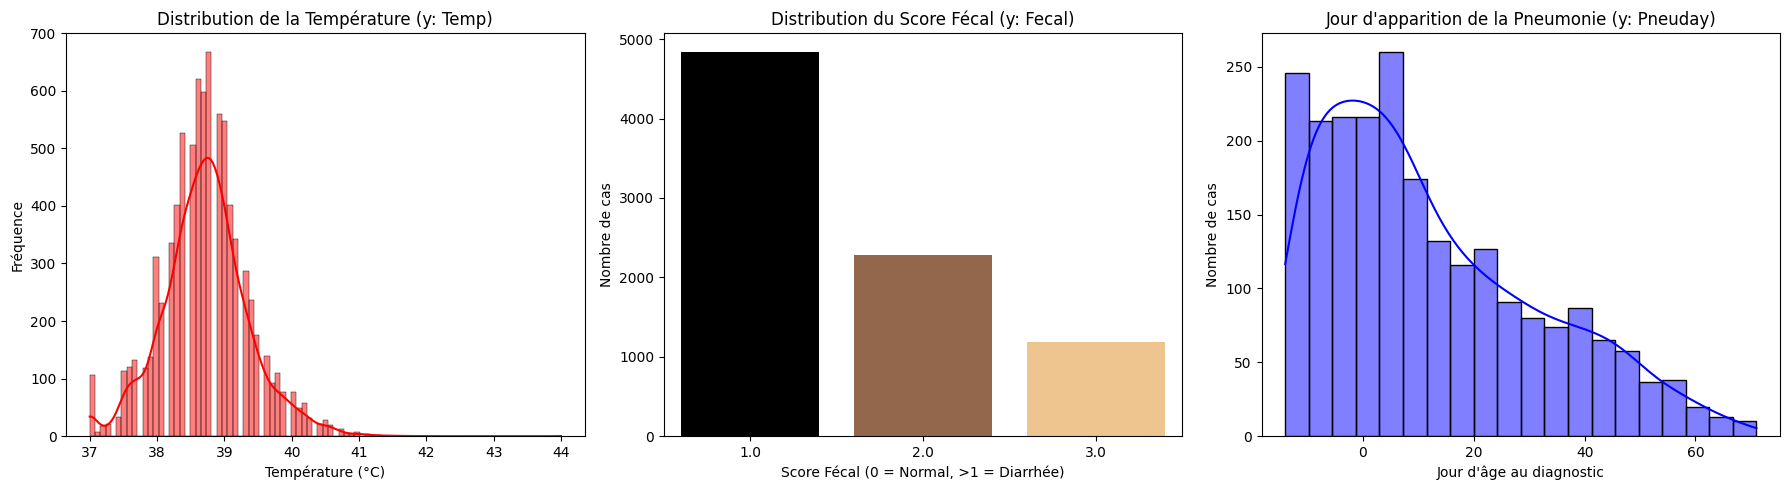

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration des graphiques pour analyser biologiquement nos variables cibles potentielles
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution de la Température (Indicateur de fièvre/infection)
sns.histplot(df['Temp'].dropna(), kde=True, ax=axes[0], color='red')
axes[0].set_title("Distribution de la Température (y: Temp)")
axes[0].set_xlabel("Température (°C)")
axes[0].set_ylabel("Fréquence")

# 2. Distribution du Score Fécal (Indicateur de santé digestive) - Utilisation d'une palette existante comme 'copper'
sns.countplot(data=df, x='Fecal', ax=axes[1], palette='copper', hue='Fecal', legend=False)
axes[1].set_title("Distribution du Score Fécal (y: Fecal)")
axes[1].set_xlabel("Score Fécal (0 = Normal, >1 = Diarrhée)")
axes[1].set_ylabel("Nombre de cas")

# 3. Distribution de la Pneumonie (Indicateur de maladie respiratoire)
sns.histplot(df['Pneuday'].dropna(), kde=True, ax=axes[2], color='blue')
axes[2].set_title("Jour d'apparition de la Pneumonie (y: Pneuday)")
axes[2].set_xlabel("Jour d'âge au diagnostic")
axes[2].set_ylabel("Nombre de cas")

plt.tight_layout()
plt.show()

In [ ]:
biologie

physiopathologie